#Análise de desempenho do Campeonato Brasileiro Série A
- Uma análise exploratória dos resultados, da eficiência dos times e da evolução do desempenho entre 2003 e 2024.

- Pergunta: Marcar mais gols está associado a um melhor desempenho no Campeonato Brasileiro?
- Análise: comparar gols marcados, pontos conquistados, posição final e desempenho dos times ao longo das temporadas.
- Resultado: entender se existe uma associação entre poder ofensivo e classificação, identificar exceções e avaliar a força dessa relação.

In [93]:
import pandas as pd
import matplotlib.pyplot as plt

In [94]:
df = pd.read_csv("brasileirao.csv")

df.head()

,season,place,team,points,played,won,draw,loss,goals,goals_taken,goals_diff
0,2003,1,Cruzeiro,100,46,31,7,8,102,47,55
1,2003,2,Santos,87,46,25,12,9,93,60,33
2,2003,3,São Paulo,78,46,22,12,12,81,67,14
3,2003,4,São Caetano,74,46,19,14,13,53,37,16
4,2003,5,Coritiba,73,46,21,10,15,67,58,9


In [95]:
df.shape

(450, 11)

In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   season       450 non-null    int64 
 1   place        450 non-null    int64 
 2   team         450 non-null    object
 3   points       450 non-null    int64 
 4   played       450 non-null    int64 
 5   won          450 non-null    int64 
 6   draw         450 non-null    int64 
 7   loss         450 non-null    int64 
 8   goals        450 non-null    int64 
 9   goals_taken  450 non-null    int64 
 10  goals_diff   450 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 38.8+ KB


In [97]:
df.isna().sum()

season         0
place          0
team           0
points         0
played         0
won            0
draw           0
loss           0
goals          0
goals_taken    0
goals_diff     0
dtype: int64

In [98]:
df.duplicated().sum()

np.int64(0)

- Criando novas váriaveis. Percentual de vitórias

In [99]:
df["percentual_vitorias"] = df["won"] / df["played"] * 100
df["media_gols_marcados"] = df["goals"] / df["played"] 
df["media_gols_sofridos"] = df["goals_taken"] / df["played"]
df["percentual_pontos"] = df["points"] / df["played"] * 100
df["saldo_calculado"] = df["goals"] / df["goals_taken"]


df


,season,place,team,points,played,won,draw,loss,goals,goals_taken,goals_diff,percentual_vitorias,media_gols_marcados,media_gols_sofridos,percentual_pontos,saldo_calculado
0,2003,1,Cruzeiro,100,46,31,7,8,102,47,55,67.391304,2.217391,1.021739,217.391304,2.170213
1,2003,2,Santos,87,46,25,12,9,93,60,33,54.347826,2.021739,1.304348,189.130435,1.550000
2,2003,3,São Paulo,78,46,22,12,12,81,67,14,47.826087,1.760870,1.456522,169.565217,1.208955
3,2003,4,São Caetano,74,46,19,14,13,53,37,16,41.304348,1.152174,0.804348,160.869565,1.432432
4,2003,5,Coritiba,73,46,21,10,15,67,58,9,45.652174,1.456522,1.260870,158.695652,1.155172
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,2024,16,Red Bull Bragantino,44,38,10,14,14,44,48,-4,26.315789,1.157895,1.263158,115.789474,0.916667
446,2024,17,Athletico Paranaense,42,38,11,9,18,40,46,-6,28.947368,1.052632,1.210526,110.526316,0.869565
447,2024,18,Criciúma,38,38,9,11,18,42,61,-19,23.684211,1.105263,1.605263,100.000000,0.688525
448,2024,19,Atlético Goianiense,30,38,7,9,22,29,58,-29,18.421053,0.763158,1.526316,78.947368,0.500000


In [100]:
df["saldo_calculado"] = (
    df["goals"] - df["goals_taken"]
)

df["saldo_calculado"].eq(df["goals_diff"]).all()


np.True_

- Conferindo a quantidade de partidas -> todo time deve ter disputado uma quantidade de partidas igual a soma de vitorias, empates e derrotas

In [101]:
df["partidas_calculadas"] = (
    df["won"] + df["draw"] + df["loss"]
)

df["partidas_calculadas"].eq(df["played"]).all()

np.True_

- Conferindo os pontos

In [102]:
df["pontos_calculados"] = (
    3 * df["won"] + df["draw"]
)

df_inconsistencias = df[
    df["points"] != df["pontos_calculados"]
]

df_inconsistencias[
    [
        "season", "team", "points",
        "won", "draw", "pontos_calculados"
    ]
]

,season,team,points,won,draw,pontos_calculados
3,2003,São Caetano,74,19,14,71
6,2003,Internacional,72,20,10,70
14,2003,Corinthians,59,15,12,57
17,2003,Juventude,53,12,14,50
18,2003,Fluminense,52,13,11,50
19,2003,Ponte Preta,50,11,18,51
21,2003,Paysandu,49,15,12,57
41,2004,São Caetano,53,23,8,77
169,2010,Grêmio Barueri,28,7,10,31
225,2013,Flamengo,45,12,13,49


- conferindo o saldo dos gols 

In [103]:
df["saldo_calculado"].eq(df["goals_diff"]).all()

np.True_

- Analisando sobre os campeões
- Filtrando apenas os campeões
- Analisando qual é o perfil estatístico de uma campanha campeã

In [104]:
filtro_campeoes = df["place"] == 1

df_campeoes = df[filtro_campeoes]

df_campeoes.shape

(22, 18)

- Calculando estatísticas descritivas 

In [105]:
colunas_metricas = [
    "points",
    "percentual_vitorias",
    "media_gols_marcados",
    "media_gols_sofridos",
    "goals_diff"
]

df_campeoes[colunas_metricas].describe().round(2)

,points,percentual_vitorias,media_gols_marcados,media_gols_sofridos,goals_diff
count,22.00,22.00,22.00,22.00,22.00
mean,78.64,59.52,1.76,0.93,32.36
std,7.56,5.59,0.26,0.21,10.11
min,67.00,50.00,1.32,0.50,14.00
25%,72.75,55.26,1.61,0.82,28.00
50%,78.50,59.61,1.74,0.92,30.50
75%,81.00,62.50,1.85,0.99,38.75
max,100.00,73.68,2.26,1.40,55.00


- Identificando os recordes dos campeões

In [106]:
df_campeoes.loc[
    df_campeoes["percentual_vitorias"].idxmax(),
    ["season", "team", "percentual_vitorias"]
]

season                      2019
team                    Flamengo
percentual_vitorias    73.684211
Name: 330, dtype: object

- Identificando a melhor defesa

In [107]:
df_campeoes.loc[
    df_campeoes["media_gols_sofridos"].idxmin(),
    ["season", "team", "media_gols_sofridos"]
]

season                      2007
team                   São Paulo
media_gols_sofridos          0.5
Name: 90, dtype: object

- O que diferencia os campeões dos demais times?
- Criando uma variável de classificação (criará uma coluna de true (campeao) e false (nao foi campeao))

In [108]:
df["campeao"] = df["place"].eq(1)

- Comparando as médias

In [109]:
colunas_comparacao = [
    "percentual_vitorias",
    "media_gols_marcados",
    "media_gols_sofridos",
    "goals_diff"
]

comparacao = (
    df.groupby("campeao")[colunas_comparacao].mean().round(2)
)

comparacao

,percentual_vitorias,media_gols_marcados,media_gols_sofridos,goals_diff
campeao,,,,
False,35.59,1.25,1.30,-1.68
True,59.52,1.76,0.93,32.36


- Calculando diferença entre os grupos acima - os que foram e os que não foram campeões

In [110]:
diferencas = (
    comparacao.loc[True] - comparacao.loc[False]
)

diferencas

percentual_vitorias    23.93
media_gols_marcados     0.51
media_gols_sofridos    -0.37
goals_diff             34.04
dtype: float64

- Criando uma variável de diferença relativa para entender a diferença percentual 

In [111]:
diferenca_relativa = (
    (comparacao.loc[True] - comparacao.loc[False])
    / comparacao.loc[False].abs() * 100
)

diferenca_relativa.round(2)

percentual_vitorias      67.24
media_gols_marcados      40.80
media_gols_sofridos     -28.46
goals_diff             2026.19
dtype: float64

- Visualizando a comparação dos gols marcados através de um boxplot

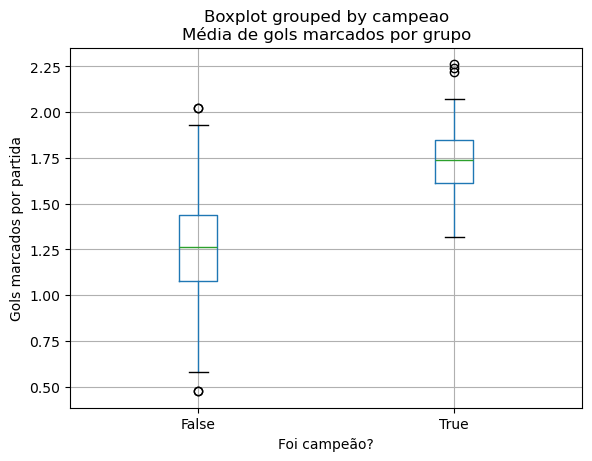

In [112]:
df.boxplot(
    column = "media_gols_marcados",
    by = "campeao"
)

plt.title("Média de gols marcados por grupo")
plt.xlabel("Foi campeão?")
plt.ylabel("Gols marcados por partida")

plt.show()

-   Analisando Ataque e Defesa: qual tem associação mais forte com a classificação?
- Investigar como essas duas características se relacionam com a posição final -> correlação
- Place na forma abaixo esta relacionada ao indicador com a posição final 

In [113]:
correlacoes = df[
    [
        "place",
        "percentual_vitorias",
        "media_gols_marcados",
        "media_gols_sofridos",
        "goals_diff"
    ]
].corr(method="spearman")

correlacoes["place"].sort_values()

percentual_vitorias   -0.945206
goals_diff            -0.900378
media_gols_marcados   -0.634139
media_gols_sofridos    0.649977
place                  1.000000
Name: place, dtype: float64

- Visualizando a correlação em um gráfico

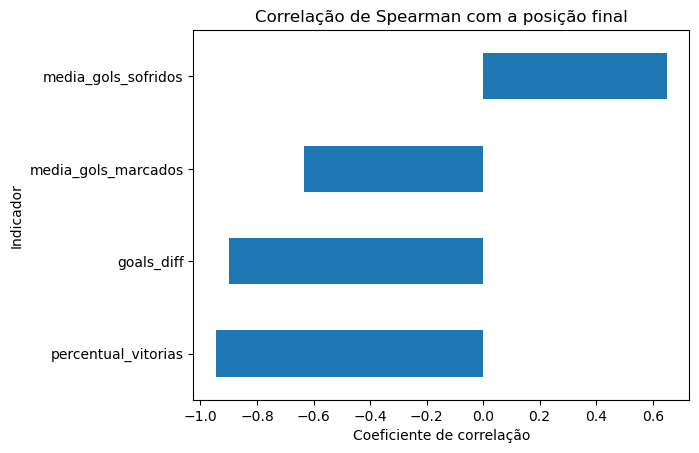

In [114]:

correlacoes_place = (
    df[
        [
            "percentual_vitorias",
            "media_gols_marcados",
            "media_gols_sofridos",
            "goals_diff"
        ]
    ]
    .corrwith(df["place"], method="spearman")
    .sort_values()
)

correlacoes_place.plot(kind="barh")

plt.title("Correlação de Spearman com a posição final")
plt.xlabel("Coeficiente de correlação")
plt.ylabel("Indicador")
plt.show()


- Como as campeão evoluíram ao longo do tempo? 
- O desempenho dos campeões mudou entre 2003 e 2024?

In [115]:
df_campeoes = (
    df[df["place"] == 1].sort_values("season").copy()
)

df_campeoes[
    [
        "season",
        "team",
        "points",
        "percentual_vitorias",
        "media_gols_marcados",
        "media_gols_sofridos",
        "goals_diff"
    ]
]

,season,team,points,percentual_vitorias,media_gols_marcados,media_gols_sofridos,goals_diff
0,2003,Cruzeiro,100,67.391304,2.217391,1.021739,55
24,2004,Santos,89,58.695652,2.239130,1.260870,45
48,2005,Corinthians,81,57.142857,2.071429,1.404762,28
70,2006,São Paulo,78,57.894737,1.736842,0.842105,34
90,2007,São Paulo,77,60.526316,1.447368,0.500000,36
110,2008,São Paulo,75,55.263158,1.736842,0.947368,30
130,2009,Flamengo,67,50.000000,1.526316,1.157895,14
150,2010,Fluminense,71,52.631579,1.631579,0.947368,26
170,2011,Corinthians,71,55.263158,1.394737,0.947368,17
190,2012,Fluminense,77,57.894737,1.605263,0.868421,28


- Criando um gráfico de pontos por temporada

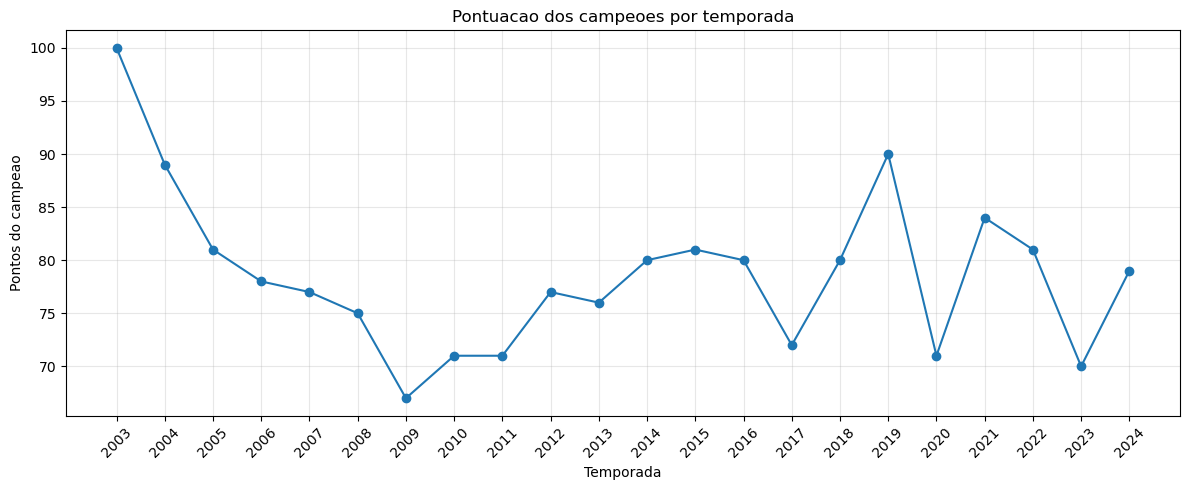

In [116]:
plt.figure(figsize=(12,5))

plt.plot(
    df_campeoes["season"],
    df_campeoes["points"],
    marker="o"
)

plt.title("Pontuacao dos campeoes por temporada")
plt.xlabel("Temporada")
plt.ylabel("Pontos do campeao")
plt.xticks(df_campeoes["season"], rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

- Calculando uma métrica para ver a diferença de pontos para o vice-campeão

In [117]:
df_top2 = df[df["place"].isin([1,2])]

pontos_top2 = df_top2.pivot(
    index="season",
    columns="place",
    values="points"
)

pontos_top2["vantagem_campeao"] = (
    pontos_top2[1] - pontos_top2 [2]
)

pontos_top2

place,1,2,vantagem_campeao
season,,,
2003,100,87,13
2004,89,86,3
2005,81,78,3
2006,78,69,9
2007,77,62,15
2008,75,72,3
2009,67,65,2
2010,71,69,2
2011,71,69,2


- Variação entre temporadas

In [118]:
df_campeoes["variacao_pontos_pct"] = (
    df_campeoes["points"].pct_change() * 100
)

df_campeoes.head()

,season,place,team,points,played,won,draw,loss,goals,goals_taken,goals_diff,percentual_vitorias,media_gols_marcados,media_gols_sofridos,percentual_pontos,saldo_calculado,partidas_calculadas,pontos_calculados,campeao,variacao_pontos_pct
0,2003,1,Cruzeiro,100,46,31,7,8,102,47,55,67.391304,2.217391,1.021739,217.391304,55,46,100,True,NaN
24,2004,1,Santos,89,46,27,8,11,103,58,45,58.695652,2.239130,1.260870,193.478261,45,46,89,True,-11.000000
48,2005,1,Corinthians,81,42,24,9,9,87,59,28,57.142857,2.071429,1.404762,192.857143,28,42,81,True,-8.988764
70,2006,1,São Paulo,78,38,22,12,4,66,32,34,57.894737,1.736842,0.842105,205.263158,34,38,78,True,-3.703704
90,2007,1,São Paulo,77,38,23,8,7,55,19,36,60.526316,1.447368,0.500000,202.631579,36,38,77,True,-1.282051


- Quais times demonstraram maior consistência histórica
- Quais equipes conquistaram mais titulos e quais aparecem com maior frequencia nas 4 primeiras colocações

In [119]:
titulos = (
    df[df["place"] == 1]["team"].value_counts()
)

titulos

team
Corinthians         4
Palmeiras           4
Cruzeiro            3
Flamengo            3
São Paulo           3
Fluminense          2
Santos              1
Atlético Mineiro    1
Botafogo            1
Name: count, dtype: int64

- Contando a presença no top 4

In [120]:
df_top4 = df[df["place"] <= 4]

presencas_top4 = (
    df_top4.groupby("team")["season"].nunique().sort_values(ascending=False)
)

presencas_top4

team
Palmeiras               11
Flamengo                10
Grêmio                  10
São Paulo               10
Internacional            7
Corinthians              7
Santos                   7
Cruzeiro                 6
Atlético Mineiro         6
Fluminense               5
Athletico Paranaense     2
Botafogo                 2
Fortaleza                2
Goiás                    1
São Caetano              1
Vasco                    1
Name: season, dtype: int64

- Considerando o número de temporadas disputadas

In [121]:
temporadas_por_time = (
    df.groupby("team")["season"].nunique()
)

taxa_top4 = (
    presencas_top4.div(temporadas_por_time).mul(100).sort_values(ascending=False)
)

taxa_top4.round(2)

team
Palmeiras               55.00
Grêmio                  50.00
Flamengo                45.45
São Paulo               45.45
Internacional           33.33
Corinthians             33.33
Santos                  33.33
Cruzeiro                31.58
Atlético Mineiro        28.57
São Caetano             25.00
Fluminense              22.73
Fortaleza               22.22
Botafogo                10.53
Athletico Paranaense     9.52
Goiás                    6.67
Vasco                    5.88
América Mineiro           NaN
América-RN                NaN
Atlético Goianiense       NaN
Avaí                      NaN
Bahia                     NaN
Brasiliense               NaN
CSA                       NaN
Ceará                     NaN
Chapecoense               NaN
Coritiba                  NaN
Criciúma                  NaN
Cuiabá                    NaN
Figueirense               NaN
Grêmio Barueri            NaN
Guarani                   NaN
Ipatinga                  NaN
Joinville                 NaN
Juven

- Visualizando os títulos

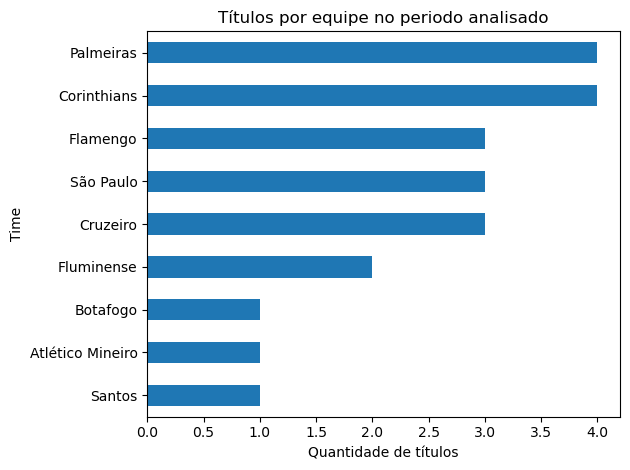

In [122]:
titulos.sort_values().plot(kind="barh")

plt.title("Títulos por equipe no periodo analisado")
plt.xlabel("Quantidade de títulos")
plt.ylabel("Time")
plt.tight_layout()

plt.show()

- Quais campeões apresentaram os resultados mais destacados em cada indicador?
- Identificando os extremos


In [123]:
metricas_extremos = {
    "points": "maior pontuacao",
    "percentual_vitorias": "maior percentual de vitorias",
    "media_gols_marcados": "maior média de gols marcados",
    "media_gols_sofridos": "menor média de gols sofridos",
    "goals_diff": "maior saldo de gols"
}

for coluna, descricao in metricas_extremos.items():

    if coluna == "media_gols_sofridos":
        indice = df_campeoes[coluna].idxmin()

    else:
        indice = df_campeoes[coluna].idxmax()

    resultado = df_campeoes.loc[
        indice,
        ["season", "team", coluna]
    ]

    print(f"\n{descricao}")
    print(resultado)


maior pontuacao
season        2003
team      Cruzeiro
points         100
Name: 0, dtype: object

maior percentual de vitorias
season                      2019
team                    Flamengo
percentual_vitorias    73.684211
Name: 330, dtype: object

maior média de gols marcados
season                     2019
team                   Flamengo
media_gols_marcados    2.263158
Name: 330, dtype: object

menor média de gols sofridos
season                      2007
team                   São Paulo
media_gols_sofridos          0.5
Name: 90, dtype: object

maior saldo de gols
season            2003
team          Cruzeiro
goals_diff          55
Name: 0, dtype: object


- Identificar a distribuição dos pontos dos campeões
- Valores atipicos podem ser identificados atraves dos iqr